# Predict NYC 311 closure hours

**Question:** Given the request details, how many hours until recorded agency closure?

This regression project follows the supplied `NYC_311_Resolution_Time_ML.ipynb` and uses the reusable implementation in `src/resolution.py`. Closure does not verify physical repair. Durations are capped at 90 days. The model outputs a point estimate rather than a guarantee.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if not (ROOT / "src").exists():
    raise RuntimeError("Open this notebook from the repository or notebooks directory")
sys.path.insert(0, str(ROOT))
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from src import resolution as R


## 1. Shared study cohort

Download the 5th, 15th and 25th of every month from January 2025 through October 2026. This is a deterministic sample, not all citywide requests. Train on January–September 2025 requests and test on January–July 2026 requests. October–December 2025 gives training requests their full 90-day follow-up before testing. Closure observations are censored at October 31, 2026. August–October 2026 filings remain in the raw cohort for description but are not fully matured model examples.


In [2]:
from src import config
AS_OF = pd.Timestamp(config.STUDY_AS_OF)
raw = R.download(R.sample_days(config.STUDY_START_DATE[:7], config.STUDY_END_DATE[:7]))
clean, audit = R.prepare(raw, AS_OF)
display(pd.Series(audit, name="Cleaning audit"))
filed = pd.to_datetime(raw.created_date, format="ISO8601", errors="coerce")
display(raw.assign(month=filed.dt.to_period("M")).groupby("month").size().rename("Sampled requests"))
display(clean.groupby(clean.created_at.dt.to_period("M")).agg(
    mature_requests=("unique_key", "size"), median_hours=(R.TARGET, "median"),
    closed_within_90d=("closed_within_90d", "mean")))


raw_rows                                                684160
outside_study_rows                                           0
duplicates_removed                                           0
invalid_rows                                               151
insufficient_followup_rows                               94791
usable_rows                                             589218
as_of                         2026-10-31T23:59:59.999999-04:00
Name: Cleaning audit, dtype: object

month
2025-01    32306
2025-02    26928
2025-03    27064
2025-04    27433
2025-05    28004
2025-06    32098
2025-07    32130
2025-08    30319
2025-09    30127
2025-10    32433
2025-11    28625
2025-12    35736
2026-01    33423
2026-02    34191
2026-03    31322
2026-04    27155
2026-05    32808
2026-06    34185
2026-07    33005
2026-08    30823
2026-09    30956
2026-10    33089
Freq: M, Name: Sampled requests, dtype: int64

,mature_requests,median_hours,closed_within_90d
created_at,,,
2025-01,32306,8.457222,0.964186
2025-02,26928,12.975556,0.960227
2025-03,27043,8.869444,0.958474
2025-04,27426,6.419167,0.951178
2025-05,27999,4.090556,0.955356
2025-06,32095,2.986389,0.958374
2025-07,32130,3.510694,0.960660
2025-08,30314,8.948056,0.953916
2025-09,30115,6.617500,0.956400


## 2. Compare four standard ML models

Compare **Linear Regression**, **Decision Tree**, **Random Forest**, and **Gradient Boosting** on the same chronological training and test sets.

Linear regression and ordinary trees use one-hot encoding fitted on training data; histogram boosting uses native categorical features. All predict log-transformed hours. The first three minimize squared log error; boosting minimizes absolute log error. These are fixed pipeline comparisons, not tuned algorithm rankings. The forest uses 100 trees, maximum depth 18 and minimum leaf size 40.

Evaluate using MAE, median absolute error and RMSE in hours. Gradient boosting remains the default; the holdout does not automatically select the deployment model. Set `RETRAIN = True` to refit all four models; otherwise this notebook reuses the saved results when available.


In [3]:
RETRAIN = False
bundle = joblib.load(R.MODEL) if R.MODEL.exists() else None
if RETRAIN or bundle is None or bundle["metadata"].get("study_id") != config.STUDY_ID:
    scores = R.train(raw, AS_OF)
    bundle = joblib.load(R.MODEL)
else:
    scores = pd.read_csv(R.REPORT / "metrics.csv")
assert set(bundle["models"]) == set(R.MODEL_NAMES)
assert set(scores["model"]) == set(R.MODEL_NAMES)
display(scores)
display(bundle["metadata"])


,model,mae_hours,median_absolute_error_hours,rmse_hours
0,linear_regression,156.368581,7.365127,438.454403
1,decision_tree,176.260890,7.462602,482.111217
2,random_forest,175.185654,7.405336,480.458123
3,gradient_boosting,151.199413,6.540660,430.377918


{'target': 'Recorded agency closure time; not verified physical resolution',
 'study_id': '2025-01_2026-10',
 'cap_hours': 2160,
 'train_rows': 266356,
 'test_rows': 226078,
 'train_start': '2025-01',
 'train_end': '2025-09',
 'test_start': '2026-01',
 'test_end': '2026-07',
 'audit': {'raw_rows': 684160,
  'outside_study_rows': 0,
  'duplicates_removed': 0,
  'invalid_rows': 151,
  'insufficient_followup_rows': 94791,
  'usable_rows': 589218,
  'as_of': '2026-10-31T23:59:59.999999-04:00'},
 'default_model': 'gradient_boosting',
 'models': ['linear_regression',
  'decision_tree',
  'random_forest',
  'gradient_boosting'],
 'target_transform': 'log1p; linear/tree/forest use squared error, boosting uses absolute error',
 'sample': '5th, 15th and 25th of each study month; local input may differ'}

## 3. Inspect errors

MAE is the average miss in hours; median absolute error describes a typical miss, and RMSE emphasizes large misses. Compare all three, since long-running cases can dominate average error. Negative signed errors mean the prediction was too early.


,agency,complaint_type,requests,mae_hours,median_signed_error_hours
156,NYPD,Illegal Parking,35309,2.039759,0.095400
160,NYPD,Noise - Residential,22062,1.942213,-0.137791
137,HPD,HEAT/HOT WATER,20974,135.239103,-8.127738
149,NYPD,Blocked Driveway,11234,2.226610,0.197444
161,NYPD,Noise - Street/Sidewalk,10427,2.025416,-0.186299
88,DOT,Street Condition,7969,252.163024,-3.821359
142,HPD,UNSANITARY CONDITION,7279,398.969950,-49.949897
15,DEP,Water System,5492,90.773147,0.000008
127,DSNY,Snow or Ice,5246,47.006953,31.216265
140,HPD,PLUMBING,4813,405.476201,-38.306367


,size,mean,median
closed_within_90d,,,
False,10573,1303.886922,1776.836888
True,215505,94.646827,5.384786


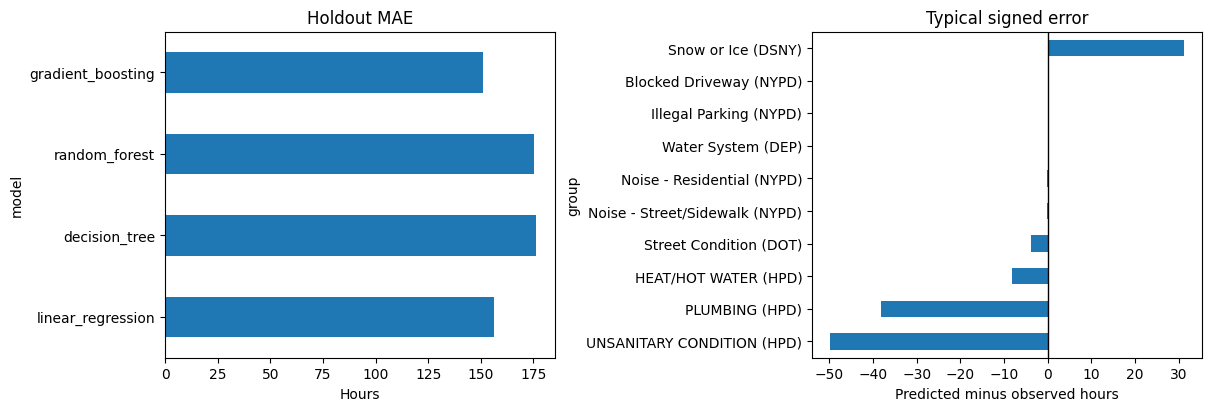

In [4]:
heldout = pd.read_parquet(R.REPORT / "holdout_predictions.parquet")
segments = pd.read_csv(R.REPORT / "errors_by_complaint.csv")
display(segments.nlargest(10, "requests"))
display(heldout.groupby("closed_within_90d").absolute_error.agg(["size", "mean", "median"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
scores.set_index("model")["mae_hours"].plot.barh(ax=axes[0], title="Holdout MAE", xlabel="Hours")
common = segments.nlargest(10, "requests").copy()
common["group"] = common.complaint_type + " (" + common.agency + ")"
common.set_index("group")["median_signed_error_hours"].sort_values().plot.barh(
    ax=axes[1], title="Typical signed error", xlabel="Predicted minus observed hours")
axes[1].axvline(0, color="black", linewidth=1)
plt.show()


## 4. Predict with any trained model

Change the input parameters and choose a model from `R.MODEL_NAMES`. ZIP codes are strings; missing and unseen categories are supported. Estimates concern recorded closure and are capped at 90 days. Accuracy on current requests needs future evaluation.


In [5]:
request = dict(agency="HPD", complaint_type="HEAT/HOT WATER",
               descriptor="ENTIRE BUILDING", borough="BROOKLYN", incident_zip="11226",
               open_data_channel_type="ONLINE", location_type="RESIDENTIAL BUILDING")
display(pd.DataFrame([R.predict(bundle, "2026-07-20 08:30", estimator=name, **request)
                      for name in R.MODEL_NAMES]))
# For a single prediction:
R.predict(bundle, "2026-07-20 08:30", estimator="random_forest", **request)


,estimated_hours,estimated_days,model,study_id,cap_hours,prediction_target,uncertainty_interval
0,23.95,1.00,linear_regression,2025-01_2026-10,2160,Recorded 311 closure,None
1,20.66,0.86,decision_tree,2025-01_2026-10,2160,Recorded 311 closure,None
2,23.16,0.97,random_forest,2025-01_2026-10,2160,Recorded 311 closure,None
3,27.69,1.15,gradient_boosting,2025-01_2026-10,2160,Recorded 311 closure,None


{'estimated_hours': 23.16,
 'estimated_days': 0.97,
 'model': 'random_forest',
 'study_id': '2025-01_2026-10',
 'cap_hours': 2160,
 'prediction_target': 'Recorded 311 closure',
 'uncertainty_interval': None}

## Limitations and next steps

- The target is official closure, not verified physical resolution.
- Selected dates and seasons may differ from the requests you want to predict.
- Values beyond 90 days are collapsed; point estimates provide no validated uncertainty range.
- Public routing/category fields can change after intake. Their original values are unavailable.
- Report the measured errors for all four models honestly; lower training error does not establish future accuracy.
- Consider rolling temporal validation, prediction intervals, and a separate model for whether closure occurs within 90 days before deploying this for user decisions.

Full instructions: `docs/Resolution_Time_ML.md`.
